# 📏 Lesson 6: Evaluating Regression Models
**Week 6 · Notebook 6 of 10 · ⏱️ about 90 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Compute by hand and in code** MAE, MSE, RMSE and R².
2. **Interpret** each metric: its units, its meaning, and its blind spots.
3. **Explain** why different metrics reward different behaviour (outlier sensitivity).
4. **Use a baseline** to judge whether a model is genuinely good.
5. **Analyse residuals** to discover *how* and *where* a model fails.
6. **Choose** the right metric for a business question.

## 🗺️ Roadmap
`Why measure?` → `Four metrics by hand` → `Outliers` → `R² and its traps` → `Baselines` → `Residual analysis` → **Problems**

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error)

---
# 📖 Part 1: "How wrong are we?"

A delivery app predicts your food will arrive in **25 minutes**. It arrives in **31**. The *error* is 6 minutes. Now imagine 10,000 deliveries with 10,000 errors: some positive, some negative, some huge, most small. We need to **boil all that down into a few honest numbers.**

The raw material is the **residual** (a.k.a. error):

$$e_i \;=\; y_i - \hat y_i \;=\; \text{actual} - \text{predicted}$$

> 🤔 **Pause & Predict.** Why can't we just *average the residuals* and call that the model's error?
>
> <details><summary>👀 Answer</summary>
> Over-predictions (negative residuals) and under-predictions (positive residuals) <b>cancel out</b>. A model that's off by +100 on one house and −100 on another has a mean error of <i>zero</i> while being terrible. We need a measure that prevents cancellation: by taking absolute values (MAE) or squares (MSE).
> </details>

---
# 📖 Part 2: Four metrics, worked by hand

### 🧑‍🏫 Worked Example 1: Five houses

A model predicts the price (in $1000s) of five houses. Here's the truth and the predictions:

| House | Actual y | Predicted ŷ | Residual e = y − ŷ | \|e\| | e² |
|---|---|---|---|---|---|
| 1 | 250 | 270 | −20 | 20 | 400 |
| 2 | 300 | 280 | +20 | 20 | 400 |
| 3 | 450 | 500 | −50 | 50 | 2,500 |
| 4 | 600 | 560 | +40 | 40 | 1,600 |
| 5 | 900 | 820 | +80 | 80 | 6,400 |
| **Sum** | | | **+70** | **210** | **11,300** |

**Mean error** (the naive way): 70 ÷ 5 = **+14**: misleadingly small because errors cancel.

**1. MAE; Mean Absolute Error** = average of |e| = 210 ÷ 5 = **42**.
 *"On average, predictions are off by $42,000."* In the target's own units. Easy to explain to anybody.

**2. MSE; Mean Squared Error** = average of e² = 11,300 ÷ 5 = **2,260**.
 Squared units (thousand-dollars²) (hard to interpret, but mathematically convenient (smooth, differentiable) it's the loss we'll minimise in Lesson 8) and it **punishes big errors heavily**.

**3. RMSE; Root Mean Squared Error** = √MSE = √2,260 ≈ **47.5**.
 Back in the target's units. Always ≥ MAE. *"A typical error is about $47,500, with large errors weighted extra."*

**4. R²; Coefficient of determination**, "the share of variation explained":

$$R^2 \;=\; 1 \;-\; \frac{SS_{res}}{SS_{tot}} \;=\; 1 - \frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$$

The mean actual price is ȳ = 500, so SS_tot = (−250)² + (−200)² + (−50)² + 100² + 400² = **275,000**, and SS_res = 11,300:  R² = 1 − 11,300 ÷ 275,000 ≈ **0.959**.

*"The model explains about 96% of the variation in prices."* Think of SS_tot as **the error of the laziest possible model**: always guess the average, and R² as *how much of that error we eliminated*. Let's check my arithmetic with code:

In [2]:
y_true = np.array([250, 300, 450, 600, 900])
y_pred = np.array([270, 280, 500, 560, 820])

resid = y_true - y_pred
print("residuals     :", resid, "  mean error =", resid.mean(), "(errors cancel!)")
print(f"MAE           : {np.abs(resid).mean():.1f}      sklearn: {mean_absolute_error(y_true, y_pred):.1f}")
print(f"MSE           : {(resid**2).mean():.1f}    sklearn: {mean_squared_error(y_true, y_pred):.1f}")
print(f"RMSE          : {np.sqrt((resid**2).mean()):.2f}     sklearn: {np.sqrt(mean_squared_error(y_true, y_pred)):.2f}")
ss_res, ss_tot = (resid**2).sum(), ((y_true - y_true.mean())**2).sum()
print(f"R²            : {1 - ss_res/ss_tot:.4f}    sklearn: {r2_score(y_true, y_pred):.4f}")

residuals     : [-20  20 -50  40  80]   mean error = 14.0 (errors cancel!)
MAE           : 42.0      sklearn: 42.0
MSE           : 2260.0    sklearn: 2260.0
RMSE          : 47.54     sklearn: 47.54
R²            : 0.9589    sklearn: 0.9589


Every number matches. These formulas are not magic; they're arithmetic on residuals.

### Summary table

| Metric | Formula | Units | Lower/higher is better | Outlier sensitivity | Say it in English |
|---|---|---|---|---|---|
| **MAE** | mean(\|e\|) | same as target | lower | low (linear) | "typical miss, in dollars" |
| **MSE** | mean(e²) | target² | lower | **high** (squared) | (used for training, not reporting) |
| **RMSE** | √mean(e²) | same as target | lower | **high** | "typical miss, big ones count extra" |
| **R²** | 1 − SS_res/SS_tot | unitless | **higher** (max 1) | high | "share of variation explained" |
| **MAPE** | mean(\|e/y\|) | % | lower | medium | "typical miss as a % of the true value" (unstable when y ≈ 0) |

---
# 📖 Part 3: Why do we have both MAE and RMSE? Outliers.

Squaring makes **one big mistake hurt far more than several small ones.** Let's see it. Ten predictions are each off by about 5 units. Now we make **just one** of them badly wrong:

In [3]:
actual = np.arange(100, 200, 10)
errors_ok = np.array([5, -4, 6, -5, 4, -6, 5, -4, 6, -5])
pred_ok = actual + errors_ok

errors_bad = errors_ok.copy(); errors_bad[-1] = 60            # ONE disaster
pred_bad = actual + errors_bad

for label, pred in [("all errors small", pred_ok), ("one error of 60", pred_bad)]:
    print(f"{label:<18}  MAE = {mean_absolute_error(actual, pred):5.2f}    RMSE = {np.sqrt(mean_squared_error(actual, pred)):5.2f}")

all errors small    MAE =  5.00    RMSE =  5.06
one error of 60     MAE = 10.50    RMSE = 19.57


A single bad prediction roughly *doubles* MAE (5 → 10.5), but RMSE nearly **quadruples** (5 → ~19.6). This gives us a rule of thumb:

* If **RMSE ≫ MAE**, you have a few large errors dominating (heavy tails).
* If RMSE ≈ MAE, errors are uniform in size.

**Choosing between them is a business decision:**

| If… | Prefer |
|---|---|
| every unit of error costs the same (e.g. delivery minutes) | **MAE** |
| big misses are disproportionately costly (e.g. under-forecasting energy demand → blackouts) | **RMSE** |
| you need a scale-free score to compare problems | **R²** or **MAPE** |

---
# 📖 Part 4: R² and its traps

R² has an enormously helpful anchor:

* **R² = 1** → perfect predictions.
* **R² = 0** → no better than always guessing the average.
* **R² < 0** → *worse* than guessing the average. (Yes, it can go negative on held-out data!)

But R² is **not a quality guarantee.** The most famous demonstration is **Anscombe's quartet**: four datasets with *identical* means, variances, correlation, regression line, and identical R² ≈ 0.67, yet utterly different stories.

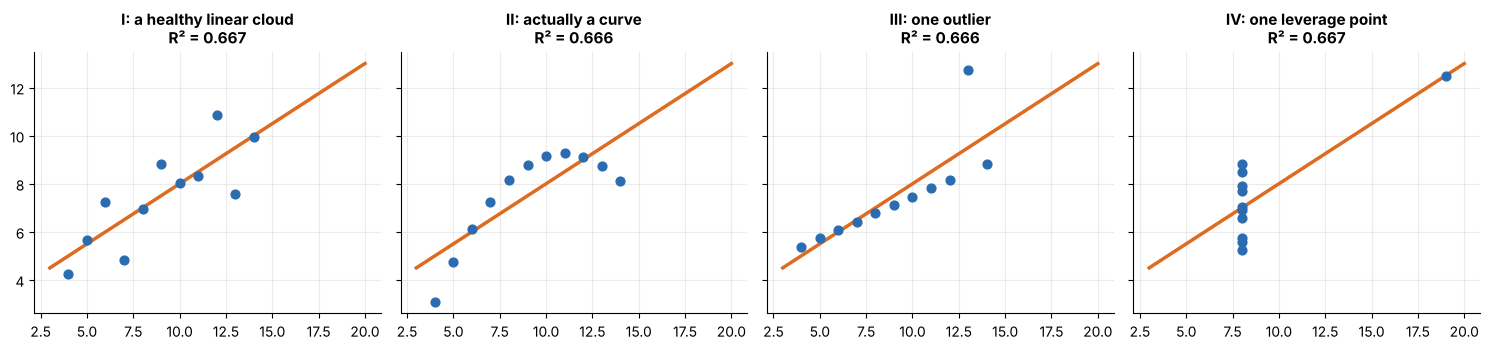

In [4]:
x123 = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], dtype=float)
sets = {
    "I: a healthy linear cloud": (x123, np.array([8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68])),
    "II: actually a curve":      (x123, np.array([9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74])),
    "III: one outlier":          (x123, np.array([7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73])),
    "IV: one leverage point":    (np.array([8]*7 + [19] + [8]*3, dtype=float),
                                  np.array([6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89])),
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (name, (x, y)) in zip(axes, sets.items()):
    m = LinearRegression().fit(x.reshape(-1, 1), y)
    ax.scatter(x, y, color=BLUE, s=40, zorder=3)
    xx = np.linspace(3, 20, 50); ax.plot(xx, m.predict(xx.reshape(-1, 1)), color=ORANGE, lw=2.5)
    ax.set_title(f"{name}\nR² = {r2_score(y, m.predict(x.reshape(-1, 1))):.3f}", fontsize=11)
plt.tight_layout(); plt.show()

**Four wildly different situations, one R².** Panel II needs a curve, III has a rogue point dragging the line, IV's slope is decided by a single far-away point. *Never trust a single number: always plot.* That brings us to residual analysis.

---
# 📖 Part 5: Baselines: "compared to what?"

> *"Our model's RMSE is 31."* Is that good? **You can't know without a reference.**

A **baseline** is the simplest sensible predictor. If your model can't beat it, it isn't learning anything useful. For regression the standard baseline is *"always predict the training-set mean"*. It scores **R² ≈ 0** by construction, so every real model must beat that.

### 🧑‍🏫 Worked Example 2: Evaluating a model properly

We'll train three models on housing and score each on **both** the training and test data (remember Lesson 4: the test score is the one that matters).

In [5]:
housing = load("housing.csv")
X, y = housing.drop(columns="price_k"), housing["price_k"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

models = {
    "Baseline (always the mean)": DummyRegressor(strategy="mean"),
    "Linear regression": LinearRegression(),
    "KNN (k=5, scaled)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    for split, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        p = model.predict(Xs)
        rows.append({"model": name, "data": split, "MAE": mean_absolute_error(ys, p),
                     "RMSE": np.sqrt(mean_squared_error(ys, p)), "R²": r2_score(ys, p)})
report = pd.DataFrame(rows).pivot(index="model", columns="data")
report = report.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
report.round(3)

data                           test                    train                
                                MAE     RMSE     R²      MAE     RMSE     R²
model                                                                       
Baseline (always the mean)  143.282  182.849 -0.000  135.342  170.928  0.000
KNN (k=5, scaled)            53.705   66.373  0.868   40.428   52.380  0.906
Linear regression            22.962   30.861  0.972   24.082   32.085  0.965

**How I read this table, out loud:**

1. **Baseline:** test R² ≈ 0 and RMSE ≈ 183: the price of ignorance. Every other model is judged against this.
2. **Linear regression:** test RMSE ≈ 31 → *an error of about $31,000 on homes averaging $480,000* (≈ 6–7%); R² ≈ 0.97. A huge improvement over the baseline, and the train and test numbers are close → **no sign of overfitting.**
3. **KNN (k=5):** better on the training data (RMSE ≈ 52) than on the test data (≈ 66) (a visible gap) and far behind linear regression on the test set. KNN averages neighbours, and the real structure here is nearly linear, so a linear model generalises better.

**Winner: linear regression**: not because it's fancy, but because it scores best on *unseen* data.

---
# 📖 Part 6: Residual analysis: look at your mistakes

Metrics summarise. **Residual plots explain.** Three plots every practitioner should make:

1. **Predicted vs. actual**: points should hug the diagonal.
2. **Residuals vs. predicted**: should look like a shapeless, horizontal band around 0. *Patterns mean the model is missing something.*
3. **Histogram of residuals**: roughly bell-shaped and centred on 0.

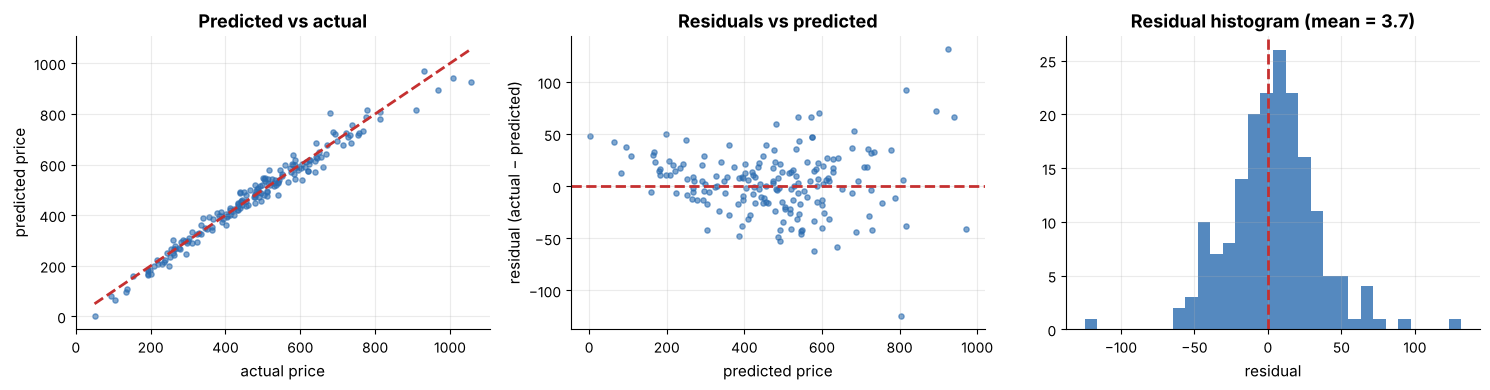

In [6]:
lin = models["Linear regression"]
pred = lin.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(y_test, pred, s=14, alpha=0.6, color=BLUE)
lims = [y_test.min(), y_test.max()]; axes[0].plot(lims, lims, color=RED, lw=2, ls="--")
axes[0].set_xlabel("actual price"); axes[0].set_ylabel("predicted price"); axes[0].set_title("Predicted vs actual")

axes[1].scatter(pred, resid, s=14, alpha=0.6, color=BLUE); axes[1].axhline(0, color=RED, lw=2, ls="--")
axes[1].set_xlabel("predicted price"); axes[1].set_ylabel("residual (actual − predicted)"); axes[1].set_title("Residuals vs predicted")

axes[2].hist(resid, bins=30, color=BLUE, alpha=0.8); axes[2].axvline(0, color=RED, lw=2, ls="--")
axes[2].set_xlabel("residual"); axes[2].set_title(f"Residual histogram (mean = {resid.mean():.1f})")
plt.tight_layout(); plt.show()

**What the plots tell us:**

* The first plot hugs the diagonal ✔: decent predictions across the price range.
* The residual-vs-predicted plot shows a **fan shape**: residuals get **wider as the predicted price rises.** The model is more uncertain about expensive houses. That makes sense: a 6% pricing noise on a $1M house is $60k, but only $12k on a $200k house. This is called **heteroscedasticity**, and it's a *discovery* the single RMSE number could never give us. It suggests we should talk about errors in **percentages** (MAPE) or model the *log* of the price.
* Residuals are centred near zero ✔: no systematic over- or under-prediction.

### Where does the model struggle most? Look at the worst cases

In [7]:
worst = (pd.DataFrame({"area_sqm": X_test["area_sqm"], "quality": X_test["neighborhood_quality"],
                       "actual": y_test, "predicted": pred.round(1), "abs_error": np.abs(resid).round(1)})
         .sort_values("abs_error", ascending=False).head(5))
worst

,area_sqm,quality,actual,predicted,abs_error
830,239.7,3,1055.9,924.4,131.5
418,174.1,4,678.8,803.3,124.5
892,170.8,4,909.1,816.5,92.6
441,229.5,2,967.1,894.5,72.6
299,150.5,3,661.7,591.8,69.9


In [8]:
print(f"MAPE (typical error as % of price): {mean_absolute_percentage_error(y_test, pred):.1%}")
print(f"RMSE as % of the average price    : {np.sqrt(mean_squared_error(y_test, pred)) / y_test.mean():.1%}")

MAPE (typical error as % of price): 5.8%
RMSE as % of the average price    : 6.5%


The worst misses are all on **pricier-than-average** houses (the test average is ≈ $475k): exactly what the fan shape predicted. Residual analysis points the way to improvement (e.g. add features that matter for luxury homes, or transform the target).

### A note on scoring names in scikit-learn
Functions such as `cross_val_score` and `GridSearchCV` always **maximise** a score. Error metrics are "lower is better", so scikit-learn flips their sign:

| Metric you want | `scoring=` string | Remember |
|---|---|---|
| R² | `"r2"` | higher is better |
| −MAE | `"neg_mean_absolute_error"` | multiply by −1 to read the MAE |
| −MSE | `"neg_mean_squared_error"` | multiply by −1 |
| −RMSE | `"neg_root_mean_squared_error"` | multiply by −1 |

### 🧭 Which metric should I report?

| Audience / goal | Report |
|---|---|
| Executives | **MAE** or MAPE ("we're typically off by $X / Y%"): plus R² for context |
| Penalising large misses | **RMSE** |
| Comparing models during tuning | the same metric consistently (RMSE or R²) |
| Always, alongside any number | the **baseline's** score, and a **residual plot** |

---
# 🧩 Your turn: Problems

### 🧩 Problem 6.1: Metrics from scratch &nbsp; ⭐⭐

Implement the four metrics using **only NumPy** (no `sklearn.metrics`): `mae(y, p)`, `mse(y, p)`, `rmse(y, p)` and `r2(y, p)`.
They should accept lists or arrays.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Convert inputs with `np.asarray(y, dtype=float)` first, then residual `e = y - p`.

</details>

<details>
<summary>💡 Hint 2</summary>

`mae = np.mean(np.abs(e))`, `mse = np.mean(e**2)`, `rmse = np.sqrt(mse)`.

</details>

<details>
<summary>💡 Hint 3</summary>

`r2 = 1 - ss_res / ss_tot` with `ss_res = np.sum(e**2)` and `ss_tot = np.sum((y - y.mean())**2)`.

</details>

In [ ]:
def mae(y, p):
    return None

def mse(y, p):
    return None

def rmse(y, p):
    return None

def r2(y, p):
    return None

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_y, _p = [250, 300, 450, 600, 900], [270, 280, 500, 560, 820]
check("MAE of the five houses is 42", lambda: abs(mae(_y, _p) - 42) < 1e-9)
check("MSE is 2260", lambda: abs(mse(_y, _p) - 2260) < 1e-9)
check("RMSE is √2260", lambda: abs(rmse(_y, _p) - 2260 ** 0.5) < 1e-9)
check("R² matches sklearn", lambda: abs(r2(_y, _p) - r2_score(_y, _p)) < 1e-9)
_rng = np.random.default_rng(3); _a, _b = _rng.normal(size=100), _rng.normal(size=100)
check("all four match sklearn on random data", lambda: all([
    abs(mae(_a, _b) - mean_absolute_error(_a, _b)) < 1e-9, abs(mse(_a, _b) - mean_squared_error(_a, _b)) < 1e-9,
    abs(r2(_a, _b) - r2_score(_a, _b)) < 1e-9]))

### 🧩 Problem 6.2: One bad apple (outlier sensitivity) &nbsp; ⭐⭐

Below are actual values and predictions for 10 items. Then **one** prediction gets badly wrong (the last item's error becomes **+100**).

Compute `mae_before`, `mae_after`, `rmse_before`, `rmse_after`, and the **growth factors** `mae_factor = mae_after / mae_before` and `rmse_factor = rmse_after / rmse_before`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Use `mean_absolute_error` and `np.sqrt(mean_squared_error(...))`, or your functions from the previous problem.

</details>

<details>
<summary>💡 Hint 2</summary>

You should find that one metric grows far more than the other. Which one, and why?

</details>

In [ ]:
actual = np.arange(200, 400, 20, dtype=float)
err = np.array([5, -4, 6, -5, 4, -6, 5, -4, 6, -5], dtype=float)
pred_before = actual + err
err_after = err.copy(); err_after[-1] = 100
pred_after = actual + err_after

mae_before = mae_after = rmse_before = rmse_after = None
mae_factor = rmse_factor = None
print(mae_factor, rmse_factor)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("MAE grows by roughly 2.5-4.5×", lambda: 2.5 < mae_factor < 4.5)
check("RMSE grows by a larger factor than MAE", lambda: rmse_factor > mae_factor)
check("RMSE grows by more than 5×", lambda: rmse_factor > 5)

### 🧩 Problem 6.3: Beat the baseline &nbsp; ⭐⭐

On the housing data (split provided), compute on the **test set**:

* `dummy_r2`: R² of `DummyRegressor(strategy="mean")` trained on the training set;
* `lin_r2`: R² of `LinearRegression`;
* `dummy_rmse`, `lin_rmse`: their RMSEs;
* `improvement_pct` = how much lower the linear model's RMSE is than the baseline's, in percent: `100 * (dummy_rmse − lin_rmse) / dummy_rmse`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`DummyRegressor(strategy="mean").fit(X_train, y_train)` ignores the features and remembers only the mean of `y_train`.

</details>

<details>
<summary>💡 Hint 2</summary>

`r2_score(y_test, model.predict(X_test))`.

</details>

In [ ]:
housing = load("housing.csv")
X, y = housing.drop(columns="price_k"), housing["price_k"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

dummy_r2 = lin_r2 = dummy_rmse = lin_rmse = improvement_pct = None
print(dummy_r2, lin_r2, improvement_pct)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("baseline R² is about 0 (between −0.05 and 0.05)", lambda: -0.05 < dummy_r2 < 0.05)
check("linear model R² above 0.95", lambda: lin_r2 > 0.95)
check("improvement_pct is correct", lambda: abs(improvement_pct - 100 * (dummy_rmse - lin_rmse) / dummy_rmse) < 1e-9)
check("RMSE dropped by more than 80%", lambda: improvement_pct > 80)

### 🧩 Problem 6.4: Hunt the biggest mistakes &nbsp; ⭐⭐

Train a `LinearRegression` on the housing training set (split provided). On the **test set**, build a DataFrame `worst` containing the **five houses with the largest absolute error**, with columns `area_sqm`, `actual`, `predicted`, `abs_error`, sorted from worst to less bad.

Also store `mean_price_of_worst`: the average *actual* price of those five, and `mean_price_all`: the average actual price in the test set.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`abs_error = np.abs(y_test - predictions)`; build a DataFrame with `X_test["area_sqm"]` and these columns.

</details>

<details>
<summary>💡 Hint 2</summary>

`.sort_values("abs_error", ascending=False).head(5)`.

</details>

In [ ]:
housing = load("housing.csv")
X, y = housing.drop(columns="price_k"), housing["price_k"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

worst = None
mean_price_of_worst = mean_price_all = None
print(worst); print(mean_price_of_worst, mean_price_all)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_pred = LinearRegression().fit(X_train, y_train).predict(X_test)
_err = np.abs(y_test.values - _pred)
check("five rows", lambda: len(worst) == 5)
check("columns are area_sqm, actual, predicted, abs_error", lambda: list(worst.columns) == ["area_sqm", "actual", "predicted", "abs_error"])
check("first row has the largest absolute error", lambda: abs(worst["abs_error"].iloc[0] - _err.max()) < 1e-6)
check("sorted from worst to less bad", lambda: worst["abs_error"].is_monotonic_decreasing)
check("the worst misses are on pricier-than-average houses", lambda: mean_price_of_worst > mean_price_all)

### 🧩 Problem 6.5: MAE or RMSE? Choose for the business &nbsp; ⭐⭐

Two delivery-time models predict the same 10 deliveries (arrays below). Compute each model's **MAE** and **RMSE** (store as `mae_A, rmse_A, mae_B, rmse_B`).

Then answer with `"A"` or `"B"` in the dictionary `choice`:

* `"typical_customer"`: we care about the *typical* error a customer experiences (every minute counts the same).
* `"avoid_disasters"`: a single very late delivery causes a lost customer, so large misses must be avoided.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Model A is almost perfect except for one big miss; Model B is mediocre but consistent. Which metric does each pattern favour?

</details>

<details>
<summary>💡 Hint 2</summary>

Lower MAE → better *typical* error. Lower RMSE → fewer large errors.

</details>

In [ ]:
actual = np.arange(20, 70, 5, dtype=float)
pred_A = actual + np.array([1, -1, 1, -1, 1, -1, 1, -1, 1, 30], dtype=float)   # nearly perfect, one disaster
pred_B = actual + np.array([7, -7, 7, -7, 7, -7, 7, -7, 7, -7], dtype=float)   # consistently so-so

mae_A = rmse_A = mae_B = rmse_B = None
choice = {"typical_customer": None, "avoid_disasters": None}
print(mae_A, rmse_A, mae_B, rmse_B)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("A has the lower MAE", lambda: mae_A < mae_B)
check("B has the lower RMSE", lambda: rmse_B < rmse_A)
check("typical customer → A", lambda: choice["typical_customer"] == "A")
check("avoid disasters → B", lambda: choice["avoid_disasters"] == "B")

### 🧩 Problem 6.6: When R² lies (Anscombe's trap) &nbsp; ⭐⭐⭐

Anscombe's dataset II (below) looks like a curve. 

1. Fit a straight-line `LinearRegression` and store its R² in `r2_linear`.
2. Fit a **quadratic** model: `make_pipeline(PolynomialFeatures(2), LinearRegression())`: and store its R² in `r2_quadratic`.
3. Store in `residual_corr` the **absolute correlation between the linear model's residuals and the centred parabola `(x - x.mean())**2`**. *(A value far from 0 means the residuals still contain a pattern the model failed to capture.)*

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Features need to be 2-D: `x.reshape(-1, 1)`.

</details>

<details>
<summary>💡 Hint 2</summary>

`np.corrcoef(a, b)[0, 1]` gives the correlation between two arrays. The residuals are `y - linear_model.predict(X2)`.

</details>

In [ ]:
x = np.array([10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5], dtype=float)
y = np.array([9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74])
X2 = x.reshape(-1, 1)

r2_linear = r2_quadratic = residual_corr = None
print(r2_linear, r2_quadratic, residual_corr)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("straight-line R² is only about 0.67", lambda: abs(r2_linear - 0.666) < 0.01)
check("quadratic R² is nearly perfect (> 0.99)", lambda: r2_quadratic > 0.99)
check("the linear residuals are strongly tied to the parabola (|corr| > 0.9)", lambda: residual_corr > 0.9)

---
## 🎟️ Exit ticket

**Q1.** A model has MAE = 12 and RMSE = 40. What does the big gap tell you?
**Q2.** Your complicated model has test R² = 0.80; a plain linear regression gets 0.78. Is it worth shipping the complicated one?
**Q3.** Can R² be negative? What would it mean?
**Q4.** Residuals plotted against predictions form a U-shape. What does that suggest?
**Q5.** Why does `cross_val_score` report `neg_root_mean_squared_error` as a negative number?

<details><summary>👀 Answers</summary>

**A1.** A few large errors dominate (the typical error is ~12, but squaring inflates the RMSE). Investigate the worst cases.
**A2.** Probably not: a gain of 0.02 is small compared with typical fold-to-fold variation, and the simpler model is easier to explain and maintain. Judge a model by its improvement over sensible baselines, not by its raw score.
**A3.** Yes, on held-out data. It means the model is worse than always predicting the mean.
**A4.** A systematic pattern: the model is missing curvature (non-linearity). Add polynomial terms or use a non-linear model.
**A5.** Scikit-learn's tools always *maximise* a score, so error metrics (lower = better) are negated.

</details>

---
## 📌 Recap: Lesson 6 on one page

* **Residual** `e = y − ŷ`. Averaging raw residuals hides errors (they cancel).
* **MAE** = mean|e| (typical miss, robust) · **MSE** = mean e² (training loss) · **RMSE** = √MSE (typical miss, big ones count extra) · **R²** = 1 − SS_res/SS_tot (share of variance explained; 0 = mean baseline).
* **RMSE ≫ MAE** ⇒ a few large errors. The right metric depends on the **cost of errors**.
* **Always compare to a baseline** (`DummyRegressor`): numbers are meaningless in isolation.
* **Plot residuals**: patterns (curves, fans) reveal what the model is missing. Same R² can hide very different stories (Anscombe).
* In scikit-learn, error metrics are negated in `scoring=` strings.

**Next up →** `07_classification_metrics.ipynb`: accuracy sounds simple… until it lies to you.